In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score, fbeta_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [ ]:
profile = pd.read_csv("Profile (1).csv")
grades = pd.read_csv("SIS_and_OASIS_Data-Grades (1).csv")
funding = pd.read_csv("updated_funding (1).csv")
program_info = pd.read_csv("Program_Info (1).csv")

In [ ]:
print("Profile:", profile.shape)
print("Grades:", grades.shape)
print("Funding:", funding.shape)
print("Program Info:", program_info.shape)

Profile: (3365, 18)
Grades: (19398, 5)
Funding: (3365, 2)
Program Info: (72, 2)


In [ ]:
profile.head()

,Program,Program Status,Student,Nationality,Age upon date of entry,Gender by Birth,Civil Status,Highest Degree Obtained,Position,Industry (old),Source of Funding,Date of Application for \nLeave of Absence/Withdrawal,Date of Last Attended Class,Last Term Attended,Week number of the term in which \nthe student last attended classes,Reason (code),Student Status,Remarks,Attrition
0,Program 36,Concluded,S0001,Filipino,34.0,Male,Single,Bachelor of Commerce,President,Printing Press / Publishing,Self-financed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1,Program 36,Concluded,S0002,Filipino,34.0,Female,Single,Bachelor of Science in Legal Management,Chief Operating Officer,Manpower,Self-financed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2,Program 36,Concluded,S0003,Filipino,32.0,Male,Single,Bachelor of Science in Entreprenuership,Vice President,Retail/General Merchandising,Self-financed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
3,Program 36,Concluded,S0004,Filipino,48.0,Male,Married,Bachelor of Science in Mechanical Engineering,President,Construction,Self-financed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
4,Program 10,On-going,S0005,Taiwan,49.0,Male,Married,Doctor of Medicine,Production Manager,Importer and wholesaler of electrical products,Self Financed,2024-09-24,2024-09-21,3,1.0,Reason I,Leave of absence,NaN,0


In [ ]:
grades.head()

,Academic Year,Student,Section & Term,Courses,Final Grade
0,AY 2018-2019,S0481,2020-T1-9,Course 180,3.50
1,AY 2018-2019,S0481,2020-T1-9,Course 247,3.50
2,AY 2018-2019,S0481,2020-T1-9,Course 255,3.00
3,AY 2018-2019,S0481,2020-T1-9,Course 370,3.75
4,AY 2018-2019,S0481,2020-T1-9,Course 449,3.50


In [ ]:
funding.head()

,Student,Financial AID received
0,S0001,NaN
1,S0002,NaN
2,S0003,NaN
3,S0004,NaN
4,S0005,NaN


In [ ]:
program_info.head()

,Code,No. of terms/sems
0,Program 01,11
1,Program 02,12
2,Program 03,8
3,Program 04,7
4,Program 05,5


In [ ]:
profile.info()
profile.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3365 entries, 0 to 3364
Data columns (total 18 columns):
 #   Column                                                               Non-Null Count  Dtype  
---  ------                                                               --------------  -----  
 0   Program                                                              3365 non-null   object 
 1   Program Status                                                       3365 non-null   object 
 2   Student                                                              3365 non-null   object 
 3   Nationality                                                          3356 non-null   object 
 4   Age upon date of entry                                               3362 non-null   float64
 5   Gender by Birth                                                      3363 non-null   object 
 6   Civil Status                                                         3365 non-null   object 
 7   Highes

,0
Program,0
Program Status,0
Student,0
Nationality,9
Age upon date of entry,3
Gender by Birth,2
Civil Status,0
Highest Degree Obtained,108
Position,359
Industry (old),629


In [ ]:
df_concluded = profile[profile["Program Status"] == "Concluded"].copy()

print("Concluded students:", df_concluded.shape)

Concluded students: (2392, 18)


In [ ]:
df_age = df_concluded.dropna(subset=["Age upon date of entry"]).copy()

bins = [0, 20, 25, 30, 35, 40, 50, 100]
labels = ["≤20", "21–25", "26–30", "31–35", "36–40", "41–50", "51+"]

df_age["Age Group"] = pd.cut(
    df_age["Age upon date of entry"],
    bins=bins,
    labels=labels
)

print("Age analysis rows:", df_age.shape)
df_age["Age Group"].value_counts().sort_index()

Age analysis rows: (2390, 19)


,count
Age Group,
≤20,6
21–25,355
26–30,677
31–35,493
36–40,377
41–50,393
51+,88


In [ ]:
df_concluded["Gender by Birth"] = df_concluded["Gender by Birth"].str.strip().str.title()

print("Gender rows:", df_concluded.shape)
df_concluded["Gender by Birth"].value_counts(dropna=False)

Gender rows: (2392, 18)


,count
Gender by Birth,
Male,1459
Female,931
NaN,2


In [ ]:
df_concluded["Civil Status"] = df_concluded["Civil Status"].str.strip().str.title()

print("Civil Status rows:", df_concluded.shape)
df_concluded["Civil Status"].value_counts(dropna=False)

Civil Status rows: (2392, 18)


,count
Civil Status,
Single,1492
Married,886
Separated,7
Not Specified,5
Divorced,1
Annulled,1


In [ ]:
df_concluded["Highest Degree Obtained"] = (
    df_concluded["Highest Degree Obtained"]
    .str.strip()
    .str.title()
)

df_concluded["Highest Degree Obtained"].value_counts().head(10)

,count
Highest Degree Obtained,
Bachelor Of Science In Accountancy,124
Bachelor Of Science In Nursing,41
Juris Doctor,39
Bachelor Of Science In Mechanical Engineering,39
Bachelor Of Science In Civil Engineering,34
Bachelor Of Science In Business Administration,32
Bachelor Of Science In Electronics And Communications Engineering,30
Bachelor Of Laws,30
Bachelor Of Science In Chemical Engineering,29


In [ ]:
df_concluded["Program"].value_counts().head(5)

,count
Program,
Program 22,91
Program 55,84
Program 43,81
Program 09,81
Program 56,81


In [ ]:
df_concluded["Reason (code)"] = (
    df_concluded["Reason (code)"]
    .astype(str)
    .str.strip()
    .str.title()
)

df_concluded["Reason (code)"].value_counts().head(5)

,count
Reason (code),
Nan,2097
Reason M,82
Reason R,46
Reason C,43
Reason A,40


In [ ]:
df_reason = df_concluded.dropna(subset=["Reason (code)"]).copy()

print("Students with recorded reason:", df_reason.shape)

df_reason["Reason (code)"].value_counts().head(5)

Students with recorded reason: (2392, 18)


,count
Reason (code),
Nan,2097
Reason M,82
Reason R,46
Reason C,43
Reason A,40


In [ ]:
df_concluded["Reason (code)"] = (
    df_concluded["Reason (code)"]
    .replace("Nan", np.nan)
)

In [ ]:
df_reason = df_concluded.dropna(subset=["Reason (code)"]).copy()

print("Students with recorded reason:", df_reason.shape)

df_reason["Reason (code)"].value_counts().head(5)

Students with recorded reason: (295, 18)


,count
Reason (code),
Reason M,82
Reason R,46
Reason C,43
Reason A,40
Reason I,28


In [ ]:
col_term = "Week number of the term in which \nthe student last attended classes"

df_term = df_concluded.dropna(subset=[col_term]).copy()

df_term[col_term] = df_term[col_term].astype(int)

df_term[col_term].value_counts().sort_index()

,count
Week number of the term in which the student last attended classes,
0,64
1,17
2,15
3,17
4,19
5,18
6,8
7,15
8,10


In [ ]:
grades.head()

,Academic Year,Student,Section & Term,Courses,Final Grade
0,AY 2018-2019,S0481,2020-T1-9,Course 180,3.50
1,AY 2018-2019,S0481,2020-T1-9,Course 247,3.50
2,AY 2018-2019,S0481,2020-T1-9,Course 255,3.00
3,AY 2018-2019,S0481,2020-T1-9,Course 370,3.75
4,AY 2018-2019,S0481,2020-T1-9,Course 449,3.50


In [ ]:
grades_clean = grades.copy()

# ensure numeric
grades_clean["Final Grade"] = pd.to_numeric(grades_clean["Final Grade"], errors="coerce")

# create fail indicator
grades_clean["Failed"] = grades_clean["Final Grade"] > 3.0

grades_clean.head()

,Academic Year,Student,Section & Term,Courses,Final Grade,Failed
0,AY 2018-2019,S0481,2020-T1-9,Course 180,3.50,True
1,AY 2018-2019,S0481,2020-T1-9,Course 247,3.50,True
2,AY 2018-2019,S0481,2020-T1-9,Course 255,3.00,False
3,AY 2018-2019,S0481,2020-T1-9,Course 370,3.75,True
4,AY 2018-2019,S0481,2020-T1-9,Course 449,3.50,True


In [ ]:
student_grades = (
    grades_clean
    .groupby("Student")
    .agg(
        total_courses=("Final Grade", "count"),
        failed_courses=("Failed", "sum"),
        avg_grade=("Final Grade", "mean")
    )
    .reset_index()
)

student_grades.shape

(803, 4)

In [ ]:
df_concluded_grades = df_concluded.merge(
    student_grades,
    on="Student",
    how="left"
)

df_concluded_grades.shape

(2392, 21)

In [ ]:
df_concluded_grades[["failed_courses", "avg_grade"]].describe()

,failed_courses,avg_grade
count,790.000000,729.000000
mean,15.649367,3.956041
std,12.842907,0.448060
min,0.000000,1.000000
25%,5.000000,3.818182
50%,11.000000,4.009615
75%,23.750000,4.225000
max,84.000000,4.726190


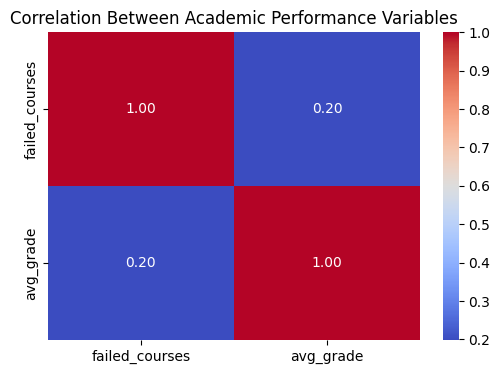

In [ ]:
# Select numeric columns for correlation
corr_cols = df_concluded_grades[
    ["failed_courses", "avg_grade"]
].dropna()

# Correlation matrix
corr_matrix = corr_cols.corr()

# Plot
plt.figure(figsize=(6, 4))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Academic Performance Variables")
plt.show()

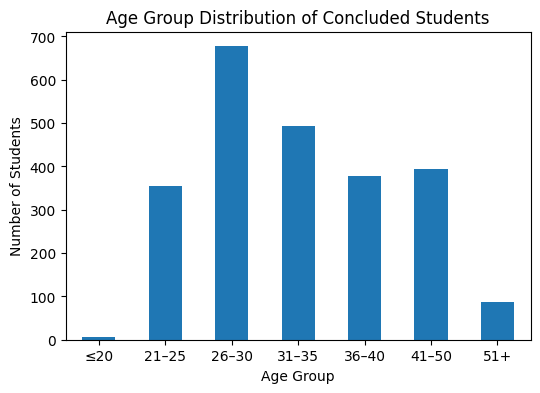

In [ ]:
df_age["Age Group"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Age Group Distribution of Concluded Students")
plt.xlabel("Age Group")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

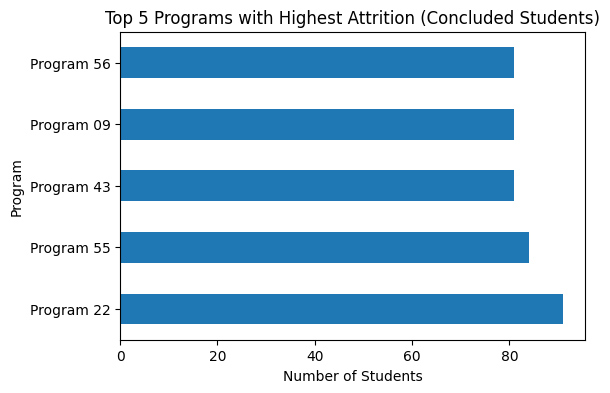

In [ ]:
df_concluded["Program"].value_counts().head(5).plot(
    kind="barh",
    figsize=(6, 4)
)

plt.title("Top 5 Programs with Highest Attrition (Concluded Students)")
plt.xlabel("Number of Students")
plt.ylabel("Program")
plt.show()

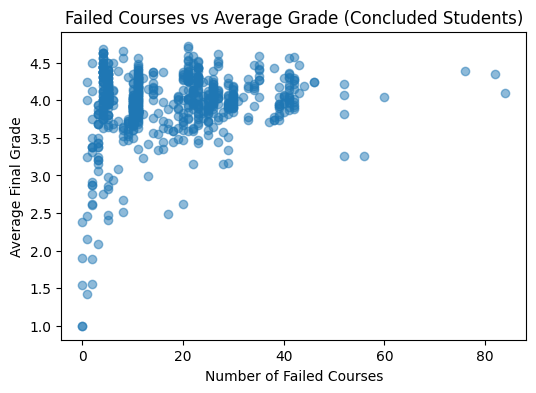

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(
    df_concluded_grades["failed_courses"],
    df_concluded_grades["avg_grade"],
    alpha=0.5
)

plt.title("Failed Courses vs Average Grade (Concluded Students)")
plt.xlabel("Number of Failed Courses")
plt.ylabel("Average Final Grade")
plt.show()

In [ ]:
profile["Attrition"] = profile["Program Status"].apply(
    lambda x: 1 if x == "Concluded" else 0
)

profile["Attrition"].value_counts()

,count
Attrition,
1,2392
0,973


In [ ]:
# Merge grades into full profile
model_df = profile.merge(
    student_grades,
    on="Student",
    how="left"
)

# Select features + target
model_df = model_df[
    ["Attrition", "failed_courses", "avg_grade"]
]

# Drop rows with missing grade info
model_df = model_df.dropna()

model_df.shape

(739, 3)

In [ ]:
X = model_df[["failed_courses", "avg_grade"]]
y = model_df["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape

((517, 2), (222, 2))

In [ ]:
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]

In [ ]:
from sklearn.metrics import recall_score, roc_auc_score, average_precision_score, fbeta_score

rf_recall = recall_score(y_test, rf_pred)
rf_roc_auc = roc_auc_score(y_test, rf_prob)
rf_pr_auc = average_precision_score(y_test, rf_prob)
rf_f2 = fbeta_score(y_test, rf_pred, beta=2)

rf_recall, rf_roc_auc, rf_pr_auc, rf_f2

(1.0,
 np.float64(0.6301369863013699),
 np.float64(0.989925981689793),
 0.9972677595628415)

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

knn_pred = knn.predict(X_test)
knn_prob = knn.predict_proba(X_test)[:, 1]

knn_recall = recall_score(y_test, knn_pred)
knn_roc_auc = roc_auc_score(y_test, knn_prob)
knn_pr_auc = average_precision_score(y_test, knn_prob)
knn_f2 = fbeta_score(y_test, knn_pred, beta=2)

knn_recall, knn_roc_auc, knn_pr_auc, knn_f2

(1.0,
 np.float64(0.6506849315068493),
 np.float64(0.9905209908410523),
 0.9972677595628415)

In [ ]:
log_reg = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

log_reg.fit(X_train, y_train)

lr_pred = log_reg.predict(X_test)
lr_prob = log_reg.predict_proba(X_test)[:, 1]

lr_recall = recall_score(y_test, lr_pred)
lr_roc_auc = roc_auc_score(y_test, lr_prob)
lr_pr_auc = average_precision_score(y_test, lr_prob)
lr_f2 = fbeta_score(y_test, lr_pred, beta=2)

lr_recall, lr_roc_auc, lr_pr_auc, lr_f2

(0.7031963470319634,
 np.float64(0.6925418569254186),
 np.float64(0.9935206376403983),
 0.7468477206595538)

In [ ]:
dt = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)
dt_prob = dt.predict_proba(X_test)[:, 1]

dt_recall = recall_score(y_test, dt_pred)
dt_roc_auc = roc_auc_score(y_test, dt_prob)
dt_pr_auc = average_precision_score(y_test, dt_prob)
dt_f2 = fbeta_score(y_test, dt_pred, beta=2)

dt_recall, dt_roc_auc, dt_pr_auc, dt_f2

(0.9954337899543378,
 np.float64(0.4977168949771689),
 np.float64(0.9864256185771094),
 0.9936189608021878)

In [ ]:
svm = SVC(
    kernel="rbf",
    probability=True,
    class_weight="balanced",
    random_state=42
)

svm.fit(X_train, y_train)

svm_pred = svm.predict(X_test)
svm_prob = svm.predict_proba(X_test)[:, 1]

svm_recall = recall_score(y_test, svm_pred)
svm_roc_auc = roc_auc_score(y_test, svm_prob)
svm_pr_auc = average_precision_score(y_test, svm_prob)
svm_f2 = fbeta_score(y_test, svm_pred, beta=2)

svm_recall, svm_roc_auc, svm_pr_auc, svm_f2

(0.8995433789954338,
 np.float64(0.5007610350076104),
 np.float64(0.9770295162691887),
 0.9162790697674419)

In [ ]:
gbm = GradientBoostingClassifier(random_state=42)

gbm.fit(X_train, y_train)

gbm_pred = gbm.predict(X_test)
gbm_prob = gbm.predict_proba(X_test)[:, 1]

gbm_recall = recall_score(y_test, gbm_pred)
gbm_roc_auc = roc_auc_score(y_test, gbm_prob)
gbm_pr_auc = average_precision_score(y_test, gbm_prob)
gbm_f2 = fbeta_score(y_test, gbm_pred, beta=2)

gbm_recall, gbm_roc_auc, gbm_pr_auc, gbm_f2

(0.9954337899543378,
 np.float64(0.5327245053272451),
 np.float64(0.9890567282497655),
 0.9936189608021878)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    fbeta_score
)
import pandas as pd

def compute_metrics(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F2-Score": fbeta_score(y_true, y_pred, beta=2),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
    }

results = {
    "Random Forest": compute_metrics(y_test, rf_pred, rf_prob),
    "Decision Tree": compute_metrics(y_test, dt_pred, dt_prob),
    "GBM": compute_metrics(y_test, gbm_pred, gbm_prob),
    "Logistic Regression": compute_metrics(y_test, lr_pred, lr_prob),
    "kNN": compute_metrics(y_test, knn_pred, knn_prob),
    "SVM": compute_metrics(y_test, svm_pred, svm_prob),
}

results_df = pd.DataFrame(results).T


results_df = results_df.sort_values(by="Recall", ascending=False)

results_df

,Accuracy,Recall,F2-Score,ROC-AUC,PR-AUC
Random Forest,0.986486,1.000000,0.997268,0.630137,0.989926
kNN,0.986486,1.000000,0.997268,0.650685,0.990521
Decision Tree,0.981982,0.995434,0.993619,0.497717,0.986426
GBM,0.981982,0.995434,0.993619,0.532725,0.989057
SVM,0.891892,0.899543,0.916279,0.500761,0.977030
Logistic Regression,0.702703,0.703196,0.746848,0.692542,0.993521


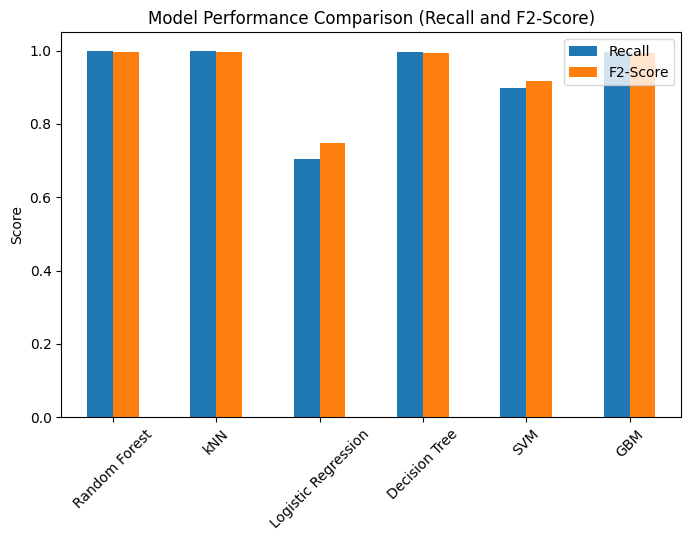

In [ ]:
model_results = {
    "Random Forest": [rf_recall, rf_f2],
    "kNN": [knn_recall, knn_f2],
    "Logistic Regression": [lr_recall, lr_f2],
    "Decision Tree": [dt_recall, dt_f2],
    "SVM": [svm_recall, svm_f2],
    "GBM": [gbm_recall, gbm_f2],
}

results_df = pd.DataFrame(
    model_results,
    index=["Recall", "F2-Score"]
).T

results_df.plot(kind="bar", figsize=(8, 5))
plt.title("Model Performance Comparison (Recall and F2-Score)")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend()
plt.show()

In [ ]:
importances = rf.feature_importances_
features = X.columns

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

importance_df

,Feature,Importance
0,failed_courses,0.506328
1,avg_grade,0.493672


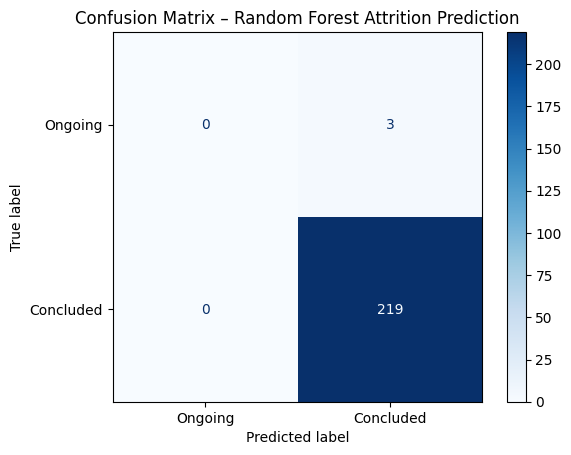

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=["Ongoing", "Concluded"],
    cmap="Blues"
)

plt.title("Confusion Matrix – Random Forest Attrition Prediction")
plt.show()

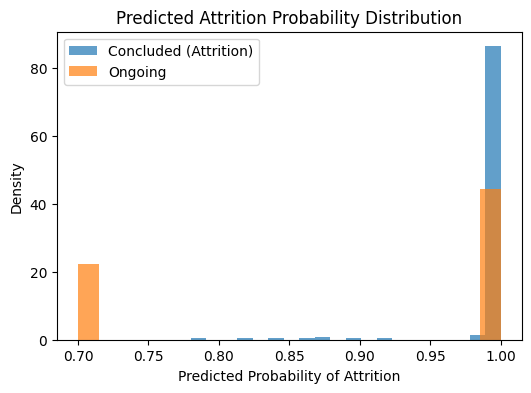

In [ ]:
plt.figure(figsize=(6, 4))

plt.hist(
    rf_prob[y_test == 1],
    bins=20,
    alpha=0.7,
    label="Concluded (Attrition)",
    density=True
)

plt.hist(
    rf_prob[y_test == 0],
    bins=20,
    alpha=0.7,
    label="Ongoing",
    density=True
)

plt.title("Predicted Attrition Probability Distribution")
plt.xlabel("Predicted Probability of Attrition")
plt.ylabel("Density")
plt.legend()
plt.show()